<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/KNN/breast_cancer_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/wisc_bc_data.csv'
df = pd.read_csv(url)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
print('Rows, columns:', df.shape)
print('Missing values:', int(df.isnull().sum().sum()))
print()
print('Diagnosis counts (B = benign, M = malignant):')
print(df['diagnosis'].value_counts())
print('Share malignant:', round((df['diagnosis'] == 'M').mean(), 3))
print()

feature_cols = [c for c in df.columns if c not in ('id', 'diagnosis')]
print('Number of features:', len(feature_cols))
print()
print('Four features with very different scales:')
df[['area_mean', 'perimeter_mean', 'smoothness_mean', 'concavity_mean']].describe().loc[['min', 'mean', 'max']].round(3)

Rows, columns: (569, 32)
Missing values: 0

Diagnosis counts (B = benign, M = malignant):
diagnosis
B    357
M    212
Name: count, dtype: int64
Share malignant: 0.373

Number of features: 30

Four features with very different scales:


,area_mean,perimeter_mean,smoothness_mean,concavity_mean
min,143.500,43.790,0.053,0.000
mean,654.889,91.969,0.096,0.089
max,2501.000,188.500,0.163,0.427


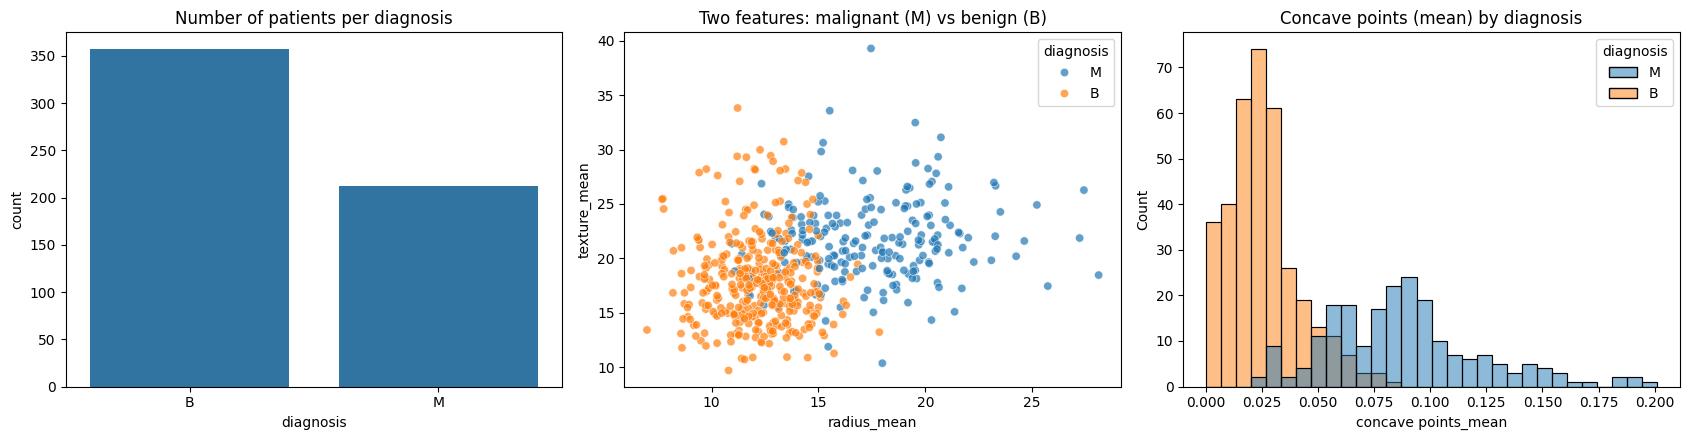

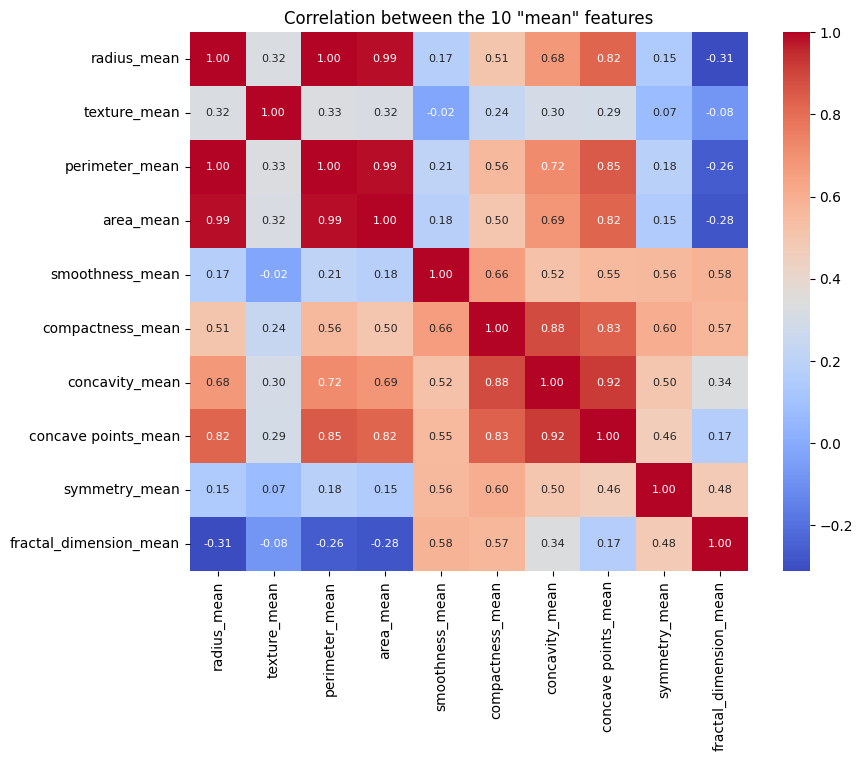

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(x='diagnosis', data=df, order=['B', 'M'], ax=axes[0])
axes[0].set_title('Number of patients per diagnosis')

sns.scatterplot(x='radius_mean', y='texture_mean', hue='diagnosis', data=df, alpha=0.7, ax=axes[1])
axes[1].set_title('Two features: malignant (M) vs benign (B)')

sns.histplot(data=df, x='concave points_mean', hue='diagnosis', bins=30, multiple='layer', alpha=0.5, ax=axes[2])
axes[2].set_title('Concave points (mean) by diagnosis')

plt.tight_layout()
plt.show()

mean_cols = [c for c in feature_cols if c.endswith('_mean')]
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 8})
plt.title('Correlation between the 10 "mean" features')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[feature_cols]
y = (df['diagnosis'] == 'M').astype(int)     # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=feature_cols, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

print('Training patients:', len(X_train), '| Test patients:', len(X_test))
print('Share malignant  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))
print()
print('Scaled training features now have mean about 0 and spread about 1:')
print('  mean of means  :', round(X_train_s.mean().mean(), 3))
print('  mean of spreads:', round(X_train_s.std(ddof=0).mean(), 3))

Training patients: 455 | Test patients: 114
Share malignant  train: 0.374  test: 0.368

Scaled training features now have mean about 0 and spread about 1:
  mean of means  : 0.0
  mean of spreads: 1.0


Share of the squared distance contributed by each feature:
                 raw features (%)  scaled features (%)
area_worst                   73.8                  3.5
area_mean                    25.4                  3.2
area_se                       0.4                  3.1
perimeter_worst               0.3                  3.5
perimeter_mean                0.1                  3.2
texture_worst                 0.0                  3.4

The top 2 raw features alone decide 99.2 % of the distance. The other 28 features share the rest.
After scaling, every feature contributes about 3.3 %.


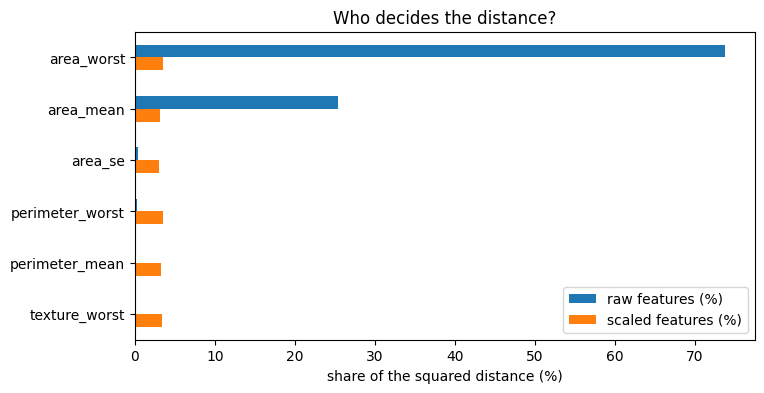

In [5]:
rng = np.random.default_rng(0)
i = rng.integers(0, len(X_train), 500)
j = rng.integers(0, len(X_train), 500)

raw_sq = ((X_train.values[i] - X_train.values[j]) ** 2).mean(axis=0)
scaled_sq = ((X_train_s.values[i] - X_train_s.values[j]) ** 2).mean(axis=0)

share = pd.DataFrame({
    'raw features (%)': raw_sq / raw_sq.sum() * 100,
    'scaled features (%)': scaled_sq / scaled_sq.sum() * 100,
}, index=feature_cols)

top = share.sort_values('raw features (%)', ascending=False).head(6)
print('Share of the squared distance contributed by each feature:')
print(top.round(1).to_string())
print()
print('The top 2 raw features alone decide', round(top['raw features (%)'].head(2).sum(), 1),
      '% of the distance. The other', len(feature_cols) - 2, 'features share the rest.')
print('After scaling, every feature contributes about', round(100 / len(feature_cols), 1), '%.')

ax = top.plot(kind='barh', figsize=(8, 4))
ax.invert_yaxis()
ax.set_xlabel('share of the squared distance (%)')
ax.set_title('Who decides the distance?')
plt.show()

In [6]:
def knn_predict_one(x, X_ref, y_ref, k=5):
    distances = np.sqrt(((X_ref - x) ** 2).sum(axis=1))   # distance to every training patient
    nearest = np.argsort(distances)[:k]                   # positions of the k closest ones
    votes = y_ref[nearest]                                # their labels (0 or 1)
    return int(votes.mean() >= 0.5)                       # majority vote (a tie counts as malignant)


Xtr, ytr = X_train_s.values, y_train.values
Xte = X_test_s.values

my_pred = np.array([knn_predict_one(x, Xtr, ytr, k=5) for x in Xte])

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

sk_pred = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train).predict(X_test_s)

print('Accuracy of my from-scratch KNN  :', round(accuracy_score(y_test, my_pred), 3))
print('Accuracy of scikit-learn KNN     :', round(accuracy_score(y_test, sk_pred), 3))
print('Predictions that are identical   :', round((my_pred == sk_pred).mean() * 100, 1), '%')

Accuracy of my from-scratch KNN  : 0.956
Accuracy of scikit-learn KNN     : 0.956
Predictions that are identical   : 100.0 %


In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, precision_score

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)


def summarize(name, model, X_te):
    p = model.predict(X_te)
    return {
        'model': name,
        'test accuracy': accuracy_score(y_test, p),
        'malignant recall': recall_score(y_test, p, zero_division=0),
        'malignant precision': precision_score(y_test, p, zero_division=0),
    }


table = pd.DataFrame([
    summarize('Baseline (always benign)', baseline, X_test),
    summarize('KNN (k=5) on raw features', knn_raw, X_test),
    summarize('KNN (k=5) on scaled features', knn_scaled, X_test_s),
])
print(table.round(3).to_string(index=False))

                       model  test accuracy  malignant recall  malignant precision
    Baseline (always benign)          0.632             0.000                0.000
   KNN (k=5) on raw features          0.912             0.786                0.971
KNN (k=5) on scaled features          0.956             0.905                0.974


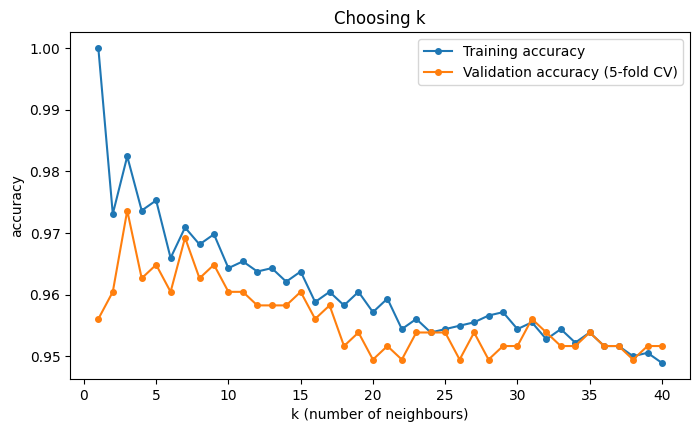

Training accuracy at k = 1       : 1.0
Best validation accuracy         : 0.974 at k = 3


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ks = list(range(1, 41))
train_acc, val_acc = [], []
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    result = cross_validate(pipe, X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True)
    train_acc.append(result['train_score'].mean())
    val_acc.append(result['test_score'].mean())

plt.figure(figsize=(8, 4.5))
plt.plot(ks, train_acc, marker='o', markersize=4, label='Training accuracy')
plt.plot(ks, val_acc, marker='o', markersize=4, label='Validation accuracy (5-fold CV)')
plt.xlabel('k (number of neighbours)')
plt.ylabel('accuracy')
plt.title('Choosing k')
plt.legend()
plt.show()

best_score = max(val_acc)
best_k = max(k for k, s in zip(ks, val_acc) if s == best_score)   # on a tie, prefer the larger (smoother) k
print('Training accuracy at k = 1       :', round(train_acc[0], 3))
print('Best validation accuracy         :', round(best_score, 3), 'at k =', best_k)

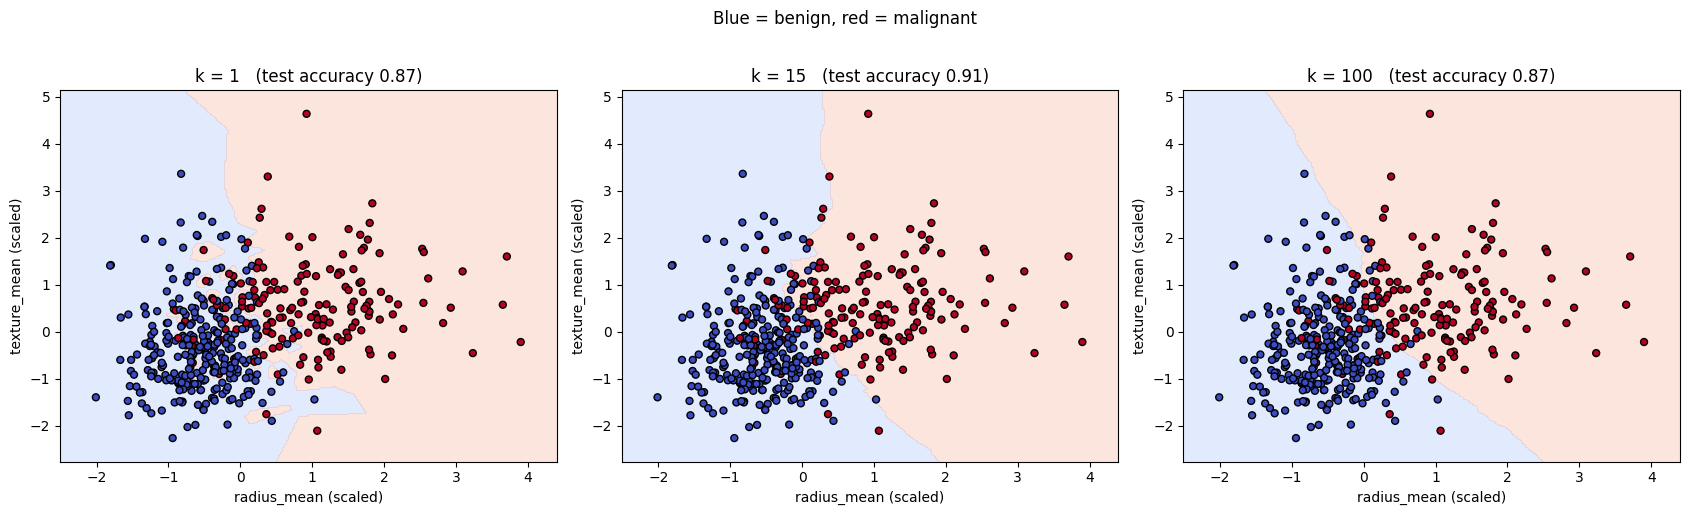

In [9]:
two = ['radius_mean', 'texture_mean']
scaler2 = StandardScaler().fit(X_train[two])
A_train = scaler2.transform(X_train[two])
A_test = scaler2.transform(X_test[two])

xx, yy = np.meshgrid(
    np.linspace(A_train[:, 0].min() - 0.5, A_train[:, 0].max() + 0.5, 250),
    np.linspace(A_train[:, 1].min() - 0.5, A_train[:, 1].max() + 0.5, 250),
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, k in zip(axes, [1, 15, 100]):
    m = KNeighborsClassifier(n_neighbors=k).fit(A_train, y_train)
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap='coolwarm', levels=[-0.5, 0.5, 1.5])
    ax.scatter(A_train[:, 0], A_train[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=25)
    ax.set_title(f'k = {k}   (test accuracy {m.score(A_test, y_test):.2f})')
    ax.set_xlabel('radius_mean (scaled)')
    ax.set_ylabel('texture_mean (scaled)')

plt.suptitle('Blue = benign, red = malignant', y=1.02)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())

param_grid = {
    'kneighborsclassifier__n_neighbors': list(range(1, 31)),
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__metric': ['euclidean', 'manhattan', 'chebyshev'],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1')
grid.fit(X_train, y_train)

best_knn = grid.best_estimator_
print('Best settings  :', grid.best_params_)
print('Best CV F1     :', round(grid.best_score_, 3))

Best settings  : {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'}
Best CV F1     : 0.967


                             model  test accuracy  malignant recall  malignant precision
          Baseline (always benign)          0.632             0.000                0.000
         KNN (k=5) on raw features          0.912             0.786                0.971
      KNN (k=5) on scaled features          0.956             0.905                0.974
KNN tuned (scaler inside pipeline)          0.965             0.905                1.000

ROC-AUC of the tuned KNN: 0.974

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



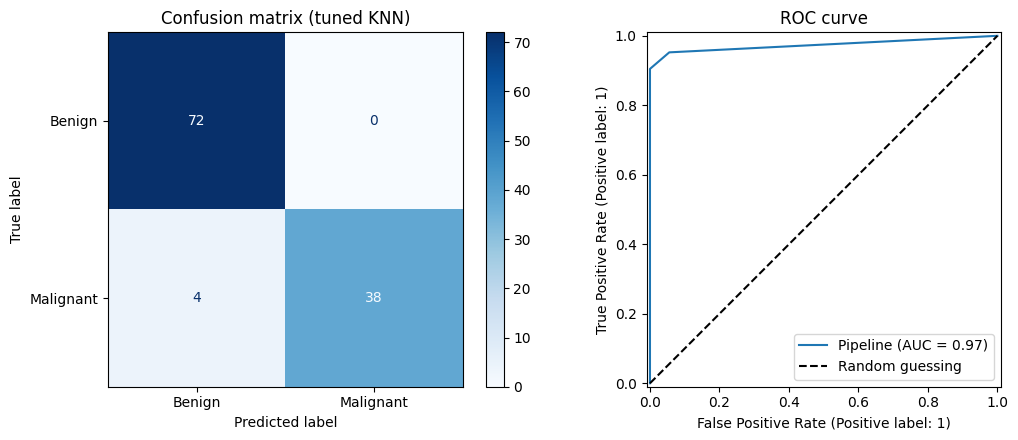

In [11]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

table = pd.DataFrame([
    summarize('Baseline (always benign)', baseline, X_test),
    summarize('KNN (k=5) on raw features', knn_raw, X_test),
    summarize('KNN (k=5) on scaled features', knn_scaled, X_test_s),
    summarize('KNN tuned (scaler inside pipeline)', best_knn, X_test),
])
print(table.round(3).to_string(index=False))
print()

pred = best_knn.predict(X_test)
proba = best_knn.predict_proba(X_test)[:, 1]
print('ROC-AUC of the tuned KNN:', round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, target_names=['Benign', 'Malignant']))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(
    best_knn, X_test, y_test, display_labels=['Benign', 'Malignant'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion matrix (tuned KNN)')

RocCurveDisplay.from_estimator(best_knn, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guessing')
axes[1].legend()
axes[1].set_title('ROC curve')

plt.tight_layout()
plt.show()

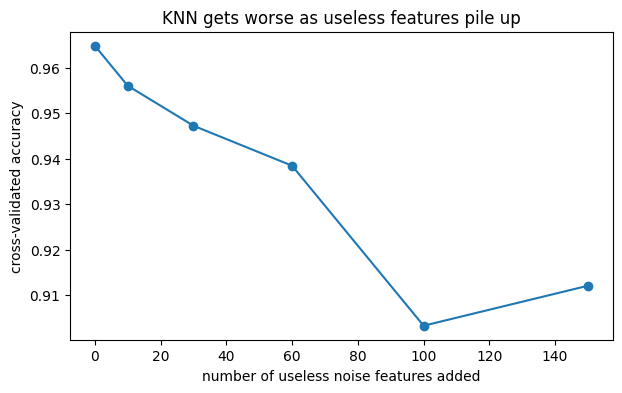

   0 noise features -> accuracy 0.965
  10 noise features -> accuracy 0.956
  30 noise features -> accuracy 0.947
  60 noise features -> accuracy 0.938
 100 noise features -> accuracy 0.903
 150 noise features -> accuracy 0.912


In [12]:
from sklearn.model_selection import cross_val_score

rng = np.random.default_rng(0)
noise_counts = [0, 10, 30, 60, 100, 150]
noise_scores = []
for m in noise_counts:
    noise = rng.normal(size=(len(X_train), m))
    X_aug = np.hstack([X_train.values, noise])
    pipe_aug = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    noise_scores.append(cross_val_score(pipe_aug, X_aug, y_train, cv=cv, scoring='accuracy').mean())

plt.figure(figsize=(7, 4))
plt.plot(noise_counts, noise_scores, marker='o')
plt.xlabel('number of useless noise features added')
plt.ylabel('cross-validated accuracy')
plt.title('KNN gets worse as useless features pile up')
plt.show()

for m, s in zip(noise_counts, noise_scores):
    print(f'{m:>4} noise features -> accuracy {s:.3f}')

In [13]:
def explain_patient(position, model=best_knn, max_show=10):
    # position = row number inside the test set
    row = X_test.iloc[[position]]
    scaler_step = model.named_steps['standardscaler']
    knn_step = model.named_steps['kneighborsclassifier']

    distances, neighbor_idx = knn_step.kneighbors(scaler_step.transform(row))
    labels = y_train.iloc[neighbor_idx[0]].values

    actual = 'Malignant' if y_test.iloc[position] == 1 else 'Benign'
    predicted = 'Malignant' if model.predict(row)[0] == 1 else 'Benign'
    p = model.predict_proba(row)[0, 1]

    print(f'   Actual: {actual} | Predicted: {predicted} | probability of malignant = {p:.2f}')
    print(f'   Its {len(labels)} nearest neighbours: {int(labels.sum())} malignant, {int((1 - labels).sum())} benign')
    for rank, (d, lab) in enumerate(zip(distances[0][:max_show], labels[:max_show]), start=1):
        print(f'     {rank:>2}. distance {d:6.2f}  ->', 'Malignant' if lab == 1 else 'Benign')


examples = [
    ('A patient who really has a malignant tumour', int(np.where(y_test.values == 1)[0][0])),
    ('A patient who really has a benign tumour', int(np.where(y_test.values == 0)[0][0])),
]
wrong = np.where(best_knn.predict(X_test) != y_test.values)[0]
if len(wrong):
    examples.append(('A patient the model got WRONG', int(wrong[0])))

for title, pos in examples:
    print(title)
    explain_patient(pos)
    print()

A patient who really has a malignant tumour
   Actual: Malignant | Predicted: Malignant | probability of malignant = 1.00
   Its 3 nearest neighbours: 3 malignant, 0 benign
      1. distance  13.86  -> Malignant
      2. distance  15.00  -> Malignant
      3. distance  15.58  -> Malignant

A patient who really has a benign tumour
   Actual: Benign | Predicted: Benign | probability of malignant = 0.00
   Its 3 nearest neighbours: 0 malignant, 3 benign
      1. distance   6.56  -> Benign
      2. distance   7.59  -> Benign
      3. distance   8.29  -> Benign

A patient the model got WRONG
   Actual: Malignant | Predicted: Benign | probability of malignant = 0.33
   Its 3 nearest neighbours: 1 malignant, 2 benign
      1. distance   7.66  -> Malignant
      2. distance   9.58  -> Benign
      3. distance  10.62  -> Benign

